In [1]:
import sys; sys.path.append('../..')
from src.modelos.dados import ler_base, preparar, dividir
from src.modelos.variaveis import criar_variaveis
from src.modelos.treino import _para_modelo, metricas, metricas_por_grupo, calibracao_por_faixa, salvar
from src.modelos.xgb import GRADE, buscar_parametros, treinar_final

base = preparar(ler_base())
treino, teste = dividir(base)
treino = criar_variaveis(treino)
teste = criar_variaveis(teste, referencia=treino)

grade = buscar_parametros(treino)
print(grade.head(5))

from src.modelos.xgb import treinar_final_completo

melhor = grade.iloc[0]
params = {k: int(melhor[k]) for k in GRADE}
m = treinar_final_completo(treino, params, int(melhor['n_arvores']))

# 3. Teste 2016 (uma vez só)
p = m.predict_proba(_para_modelo(teste))[:, 1]
print('\nTeste:', metricas(teste['default'], p))
print(metricas_por_grupo(teste, p, 'pais'))
print(calibracao_por_faixa(teste['default'], p))

import sys; sys.path.insert(0, '../../src/dados')
from pathlib import Path
from carga_macro import _ler_euribor
from src.modelos.prever import montar_pacote, salvar_pacote

import joblib
e12 = joblib.load('../../modelos_salvos/pacote_prever_v1.joblib')['euribor_12m']
print(e12.index.min(), e12.index.max(), len(e12))
pac = montar_pacote(m, treino, e12)
print(salvar_pacote(pac))

import json
from src.modelos.prever import prever
from tests.modelos.test_contrato_prever import validar_saida_prever

for _, linha in teste.sample(5, random_state=1).iterrows():
    saida = prever(linha.to_dict(), pac)
    validar_saida_prever(saida)
    print(json.dumps(saida, ensure_ascii=False, indent=1)[:600], '\n')

salvar(m, 'xgboost_v2', {'params': params, 'teste': metricas(teste['default'], p)})

c:\dev\Auditor-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


   max_depth  min_child_weight  reg_lambda  n_arvores  contratos  \
0          3                 5           1        161       5943   
1          4                20           1         99       5943   
2          4                20          10        122       5943   
3          5                20           1         94       5943   
4          5                20          10        101       5943   

   default_real  default_previsto     auc      ks   brier  
0        0.6655            0.6620  0.7162  0.3251  0.1914  
1        0.6655            0.6610  0.7161  0.3283  0.1916  
2        0.6655            0.6623  0.7160  0.3263  0.1915  
3        0.6655            0.6616  0.7156  0.3289  0.1917  
4        0.6655            0.6591  0.7156  0.3303  0.1917  

Teste: {'contratos': 7311, 'default_real': 0.6708, 'default_previsto': 0.5516, 'auc': 0.7208, 'ks': 0.3302, 'brier': 0.204}
      contratos  default_real  default_previsto     auc      ks   brier
pais                              

WindowsPath('C:/dev/Auditor-Project/modelos_salvos/xgboost_v2.joblib')

                               contratos  default_real  default_previsto  \
nosso_modelo                      7311.0        0.6708            0.5516   
pd_bondora                        7311.0        0.6708            0.3360   
nosso_modelo_mesmos_contratos     7311.0        0.6708            0.5516   

                                  auc      ks   brier  
nosso_modelo                   0.7208  0.3302  0.2040  
pd_bondora                     0.6697  0.2490  0.3226  
nosso_modelo_mesmos_contratos  0.7208  0.3302  0.2040  


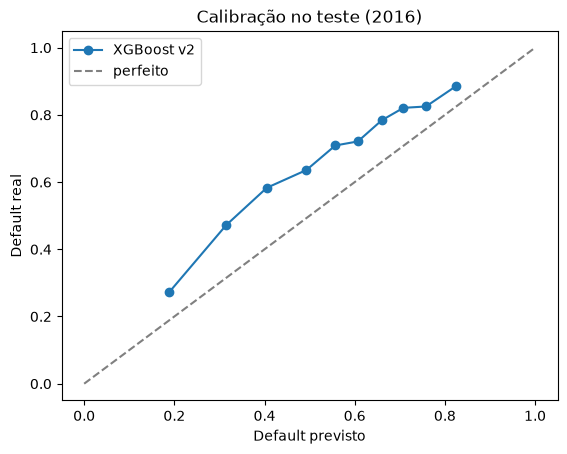

In [2]:
import matplotlib.pyplot as plt
from src.modelos.treino import comparar_com_bondora

print(comparar_com_bondora(teste, p))

c = calibracao_por_faixa(teste['default'], p)
plt.plot(c['prevista'], c['real'], 'o-', label='XGBoost v2')
plt.plot([0, 1], [0, 1], '--', color='gray', label='perfeito')
plt.xlabel('Default previsto'); plt.ylabel('Default real')
plt.title('Calibração no teste (2016)'); plt.legend(); plt.show()